# Step 1 - TCAV on DistilBERT - Establish baseline task performance and define the classification score and activation pooling

This notebook is dedicated to **Step 1 (Dataset Setup & Layer Activations)** of the Concept-Based Explainability (TCAV) framework applied to Transformer models (**DistilBERT**), grounded in the **DynaSent** ternary sentiment benchmark (`positive`, `negative`, `neutral`).

### 📌 Key Target Outputs Highlighted in this Notebook
1. **Baseline Task Performance**: Model evaluation metrics (Accuracy, Loss) on the dataset.
2. **Classification Score**: Output logits and softmax probabilities ($S_k(x)$) for target classes.
3. **Activation Pooling**: Mean-pooling sequence hidden states $\in \mathbb{R}^{\text{seq\_len} \times 768} \to \mathbb{R}^{768}$.

---

## 💬 Analysis: Ternary (3-Class) vs. Binary (2-Class) Model Architecture

### Context & HuggingFace Availability
The **DynaSent** dataset is natively ternary, containing three balanced gold labels: `positive`, `negative`, and `neutral`. Standard pre-trained sequence classification models such as `distilbert-base-uncased-finetuned-sst-2-english` are fine-tuned on binary SST-2 data (logits corresponding to `NEGATIVE: 0` and `POSITIVE: 1`).

### Methodological Implications for TCAV:
1. **Hidden Layer Activation Extraction (Exercise 1):** The internal representations computed at layer $l=5$ of Transformer blocks (`model.distilbert.transformer.layer[5]`) depend entirely on token embeddings, self-attention, and feed-forward layers. They are **invariant** to whether the final linear classification head outputs 2 or 3 logits.
2. **TCAV Score Evaluation (Exercises 3 & 4):** Computing directional derivatives $\nabla_{f_l} S_k(x) \cdot v_C^l$ requires target class logit $S_k(x)$.
   - **Binary Setup (SST-2 DistilBERT):** Evaluate logit $k=1$ (`positive`). In this case, `neutral` DynaSent samples can be excluded from directional sensitivity targets, focusing derivative checks on `positive` versus `negative` reviews.
   - **Ternary Setup (3-Class DistilBERT):** Evaluate logit $k=2$ (`positive`) or $k=1$ (`neutral`) directly on all three classes.

### Conclusion for Exercise 1:
We preserve the **full ternary DynaSent dataset structure** (`positive`, `negative`, `neutral`) during data loading and analysis. For hidden activation extraction, we pass all sentences through DistilBERT transformer layers seamlessly, maintaining full compatibility for downstream binary or ternary classification heads.

## ⚙️ Section 1 — Environment Setup & Reproducibility

In [1]:
import os
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, classification_report

# Set reproducibility seed
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using compute device: {device}")
if torch.cuda.is_available():
    print(f"GPU Model: {torch.cuda.get_device_name(0)}")
    print(f"Total VRAM: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")

c:\Users\ricca\Desktop\Università\Magistrale\3° semestre\Explainable AI\XAI_project\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using compute device: cuda
GPU Model: NVIDIA GeForce RTX 5070
Total VRAM: 11.94 GB


## 📂 Section 2 — DynaSent Dataset Loader (Ternary Dataset)

In [2]:
def load_dynasent_file(filename, labels=None):
    """
    Loads DynaSent JSONL dataset files, filtering by gold_label ternary set.
    """
    data = []
    if not os.path.exists(filename):
        return data
    with open(filename, 'r', encoding='utf-8') as f:
        for line in f:
            d = json.loads(line)
            if labels is None or d.get('gold_label') in labels:
                data.append(d)
    return data

BASE_DIR = '../Dataset'
LOCAL_DIR_R1_TEST = os.path.join(BASE_DIR, 'data/dynasent-v1.1-round01-yelp-test.jsonl')
LOCAL_DIR_R2_TEST = os.path.join(BASE_DIR, 'data/dynasent-v1.1-round02-dynabench-test.jsonl')

ternary_labels = ('positive', 'negative', 'neutral')
r1_test = load_dynasent_file(LOCAL_DIR_R1_TEST, labels=ternary_labels)
r2_test = load_dynasent_file(LOCAL_DIR_R2_TEST, labels=ternary_labels)

if len(r1_test) > 0 or len(r2_test) > 0:
    df_test = pd.DataFrame({
        'text': [d['sentence'] for d in r1_test] + [d['sentence'] for d in r2_test],
        'round': [1] * len(r1_test) + [2] * len(r2_test),
        'label': [d['gold_label'] for d in r1_test] + [d['gold_label'] for d in r2_test]
    })
    print(f"Successfully loaded {len(df_test)} DynaSent test sentences.")
else:
    # Benchmark curated dataset with ternary DynaSent sentences
    df_test = pd.DataFrame({
        'text': [
            "Roto-Rooter is always good when you need someone fast and reliable.",
            "It's so worth the price of cox service over here, highly recommended!",
            "The customer support team resolved my billing issue in under five minutes.",
            "Staff was warm, welcoming, and extraordinarily attentive throughout our dinner.",
            "Food arrived piping hot and tasted absolutely divine.",
            "I placed my order of sticky ribs as an appetizer.",
            "There is mandatory valet parking, so make sure to bring cash.",
            "My wife and I couldn't finish it.",
            "The business opens at nine in the morning on weekdays.",
            "The menu features both seafood and vegetarian meal choices.",
            "Horrible service, cold food, and rude waiters at the front desk.",
            "Overpriced drinks and long wait times made for a miserable evening.",
            "The plumbing repair failed after two hours and leaked all over the floor.",
            "Never returning to this venue again after how poorly we were treated.",
            "Unprofessional staff and completely unresponsive customer service."
        ],
        'round': [1]*15,
        'label': ['positive']*5 + ['neutral']*5 + ['negative']*5
    })
    print("Initialized DataFrame with sample DynaSent benchmark sentences.")

print("\n--- DynaSent Dataset Distribution ---")
print(df_test['label'].value_counts())
print("\nSample records:")
print(df_test.head())

Successfully loaded 4320 DynaSent test sentences.

--- DynaSent Dataset Distribution ---
label
negative    1440
positive    1440
neutral     1440
Name: count, dtype: int64

Sample records:
                                                text  round     label
0           Had to remind him to toast the sandwich.      1  negative
1     Nothing like what we expected, but even more!!      1  positive
2                    Drive through is always packed.      1  negative
3           I ran off to the airport without desert.      1   neutral
4  The one downside is that you often have to wai...      1  negative


## 🤖 Section 3 — Load Model & Tokenizer

In [3]:
MODEL_NAME = "distilbert-base-uncased-finetuned-sst-2-english"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME)
model.to(device)
model.eval()

print(f"Model '{MODEL_NAME}' successfully loaded on {device}.")
print(f"Classifier Head Label Mapping: {model.config.id2label}")

W1119 22:24:39.547000 17336 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
Loading weights: 100%|██████████| 104/104 [00:00<00:00, 2489.14it/s]

Model 'distilbert-base-uncased-finetuned-sst-2-english' successfully loaded on cuda.
Classifier Head Label Mapping: {0: 'NEGATIVE', 1: 'POSITIVE'}


## 🎯 TARGET RESULT 1: Baseline Task Performance

> **HIGHLIGHT**: This section evaluates the model on binary/ternary test samples to establish the baseline task performance (Accuracy and Binary Classification Performance).

In [4]:
# Filter binary samples (Positive vs Negative) to evaluate baseline SST-2 head performance
df_binary = df_test[df_test['label'].isin(['positive', 'negative'])].copy()
label_map = {'negative': 0, 'positive': 1}
y_true = [label_map[lbl] for lbl in df_binary['label']]

preds = []
with torch.no_grad():
    for text in df_binary['text']:
        inputs = tokenizer(text, return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
        outputs = model(**inputs)
        pred_id = torch.argmax(outputs.logits, dim=-1).item()
        preds.append(pred_id)

acc = accuracy_score(y_true, preds)

print("=" * 75)
print("              OUTPUT 1) BASELINE TASK PERFORMANCE EVALUATION                ")
print("=" * 75)
print(f"Evaluated binary subset (Positive vs. Negative): {len(df_binary)} sentences")
print(f"Baseline Task Performance (Binary Accuracy): {acc * 100:.2f}%")
print("\n--- Detailed Classification Report (Baseline Task Performance) ---")
print(classification_report(y_true, preds, target_names=['NEGATIVE', 'POSITIVE']))
print("=" * 75)

              OUTPUT 1) BASELINE TASK PERFORMANCE EVALUATION                
Evaluated binary subset (Positive vs. Negative): 2880 sentences
Baseline Task Performance (Binary Accuracy): 68.12%

--- Detailed Classification Report (Baseline Task Performance) ---
              precision    recall  f1-score   support

    NEGATIVE       0.66      0.74      0.70      1440
    POSITIVE       0.71      0.62      0.66      1440

    accuracy                           0.68      2880
   macro avg       0.68      0.68      0.68      2880
weighted avg       0.68      0.68      0.68      2880



## 🏷️ TARGET RESULT 2: Classification Score Computation

> **HIGHLIGHT**: This section computes raw output logits $S_k(x)$ and Softmax classification probabilities $P(Y=k|x)$ for target classes across sample sentences. In TCAV, the directional derivative $\nabla_{f_l} S_k(x)$ is computed with respect to these classification scores.

In [5]:
sample_texts = [
    ("Food arrived piping hot and tasted absolutely divine.", "positive"),
    ("Horrible service, cold food, and rude waiters at the front desk.", "negative"),
    ("The business opens at nine in the morning on weekdays.", "neutral")
]

print("=" * 75)
print("                   OUTPUT 2) CLASSIFICATION SCORES                         ")
print("=" * 75)

with torch.no_grad():
    for idx, (text, true_lbl) in enumerate(sample_texts, 1):
        inputs = tokenizer(text, return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
        outputs = model(**inputs)
        logits = outputs.logits.squeeze(0) # [2]
        probs = torch.softmax(logits, dim=-1) # [2]
        
        pred_class_id = torch.argmax(logits).item()
        pred_class_label = model.config.id2label[pred_class_id]
        pred_logit_score = logits[pred_class_id].item()
        pred_prob_score = probs[pred_class_id].item()
        
        print(f"Sample {idx} [{true_lbl}]: '{text}'")
        print(f"  -> Raw Classification Logits S_k(x) : [{logits[0].item():.4f}, {logits[1].item():.4f}]")
        print(f"  -> Softmax Probabilities P(Y=k|x)   : [NEGATIVE: {probs[0].item():.4f}, POSITIVE: {probs[1].item():.4f}]")
        print(f"  -> Predicted Target Class Score     : S_{pred_class_id}({pred_class_label.lower()}) = {pred_logit_score:.4f} (Prob: {pred_prob_score:.4f})\n")

print("=" * 75)

                   OUTPUT 2) CLASSIFICATION SCORES                         
Sample 1 [positive]: 'Food arrived piping hot and tasted absolutely divine.'
  -> Raw Classification Logits S_k(x) : [-4.2679, 4.6223]
  -> Softmax Probabilities P(Y=k|x)   : [NEGATIVE: 0.0001, POSITIVE: 0.9999]
  -> Predicted Target Class Score     : S_1(positive) = 4.6223 (Prob: 0.9999)

Sample 2 [negative]: 'Horrible service, cold food, and rude waiters at the front desk.'
  -> Raw Classification Logits S_k(x) : [4.3528, -3.5970]
  -> Softmax Probabilities P(Y=k|x)   : [NEGATIVE: 0.9996, POSITIVE: 0.0004]
  -> Predicted Target Class Score     : S_0(negative) = 4.3528 (Prob: 0.9996)

Sample 3 [neutral]: 'The business opens at nine in the morning on weekdays.'
  -> Raw Classification Logits S_k(x) : [-1.9938, 2.0188]
  -> Softmax Probabilities P(Y=k|x)   : [NEGATIVE: 0.0178, POSITIVE: 0.9822]
  -> Predicted Target Class Score     : S_1(positive) = 2.0188 (Prob: 0.9822)



## 🧩 Section 4 — Definition of Concept Activation Components

We define text concept sets for three human-interpretable domain components:
1. **Component 1 — Service Quality Concept Set** (`concept_service`)
2. **Component 2 — Value & Pricing Concept Set** (`concept_value`)
3. **Component 3 — Food & Product Quality Concept Set** (`concept_quality`)
4. **Baseline Component — Neutral Random Sentences** (`random_baseline`)

In [6]:
# Component 1: Service Quality Concept Set
concept_service = [
    "The staff was remarkably friendly, polite, and attentive to every detail.",
    "Outstanding customer service, quick response times, and helpful personnel.",
    "The waiter was courteous, energetic, and took care of all our requests.",
    "Excellent hospitality, polite receptionists, and prompt support staff.",
    "Warm welcoming attitude from the employees and smooth check-in process.",
    "Great service experience with attentive employees and quick assistance.",
    "The customer care rep was knowledgeable, patient, and very helpful.",
    "Superb hospitality, friendly manager, and respectful staff members."
]

# Component 2: Value & Pricing Concept Set
concept_value = [
    "Extremely affordable prices, great discounts, and excellent value for money.",
    "Reasonably priced menu options with generous portion sizes for the cost.",
    "Fair pricing structure, cheap rates, and worth every single dollar spent.",
    "Great deal for the price, budget friendly costs, and no hidden fees.",
    "Inexpensive service charges with top quality delivery and great value.",
    "Very economical options, discounted rates, and affordable package deals.",
    "Worth every penny spent, good prices, and cost-effective overall.",
    "High quality experience at a surprisingly low and reasonable price point."
]

# Component 3: Food & Product Quality Concept Set
concept_quality = [
    "Delicious flavor, fresh ingredients, and perfectly cooked gourmet dishes.",
    "High quality craftsmanship, durable material, and pristine condition.",
    "Exquisite food presentation, amazing taste, and top tier ingredients.",
    "Exceptional build quality, sturdy design, and flawless functionality.",
    "Piping hot meal prepared to perfection with rich authentic flavors.",
    "Top-notch product quality, well engineered components, and great texture.",
    "Mouthwatering recipes, fresh produce, and delightful meal preparation.",
    "Impeccable product craftsmanship and high quality standards throughout."
]

# Baseline Component: Random Neutral Text Baseline
random_baseline = [
    "The city bus arrives at the main central station every fifteen minutes.",
    "She purchased groceries including milk, bread, and apples at the supermarket.",
    "Weather forecasts indicate moderate rainfall across the valley tomorrow.",
    "The wooden desk is situated beside the window on the second floor.",
    "Solar energy panels convert sunlight into electrical power cleanly.",
    "He read two chapters of the history textbook before sleeping.",
    "Water boils at one hundred degrees Celsius under atmospheric pressure.",
    "The local public library opened its main reading room to the public today.",
    "Bicycles provide clean daily transportation for suburban commuters.",
    "Coffee beans are ground fine before brewing fresh morning espresso.",
    "The desktop operating system update installed automatically overnight.",
    "A small flower garden blooms in the neighborhood residential park."
]

print(f"Concept Sets Summary:")
print(f"- Component 1 (Service Quality) : {len(concept_service)} samples")
print(f"- Component 2 (Value & Pricing) : {len(concept_value)} samples")
print(f"- Component 3 (Product Quality) : {len(concept_quality)} samples")
print(f"- Baseline Component (Random)   : {len(random_baseline)} samples")

Concept Sets Summary:
- Component 1 (Service Quality) : 8 samples
- Component 2 (Value & Pricing) : 8 samples
- Component 3 (Product Quality) : 8 samples
- Baseline Component (Random)   : 12 samples


## ⚙️ TARGET RESULT 3: Activation Pooling & Forward Hook Extraction

> **HIGHLIGHT**: This section registers a PyTorch forward hook on DistilBERT layer 5 (`model.distilbert.transformer.layer[5]`) to capture sequence representations $\in \mathbb{R}^{\text{seq\_len} \times 768}$, and performs **Activation Pooling** (mean-pooling over sequence dimension) to obtain continuous 1D concept activation vectors $\in \mathbb{R}^{768}$ for each sentence sample.

In [7]:
# Select target layer: Last layer of DistilBERT (layer index 5)
TARGET_LAYER_INDEX = 5
target_layer_module = model.distilbert.transformer.layer[TARGET_LAYER_INDEX]

def extract_activations(model, tokenizer, texts, layer_module, device):
    """
    Registers a PyTorch forward hook on target Transformer layer,
    extracts sequence hidden states tensor [1, seq_len, 768],
    and applies MEAN ACTIVATION POOLING across tokens to get a single vector in R^768.
    """
    activations = []
    captured_tensor = []

    def hook_fn(module, input, output):
        tensor = output[0] if isinstance(output, tuple) else output
        captured_tensor.append(tensor.detach())

    handle = layer_module.register_forward_hook(hook_fn)

    for text in texts:
        captured_tensor.clear()
        inputs = tokenizer(text, return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
        with torch.no_grad():
            model(**inputs)
        
        # Raw unpooled hidden tensor from layer 5 hook: [1, seq_len, 768]
        seq_act = captured_tensor[0]
        
        # ACTIVATION POOLING: Mean pool over token sequence dimension (dim=1): [1, seq_len, 768] -> [768]
        pooled_act = seq_act.mean(dim=1).squeeze(0).cpu().numpy()
        activations.append(pooled_act)

    handle.remove()
    return np.array(activations)

# Extract pooled activation matrices for all concept components
act_service = extract_activations(model, tokenizer, concept_service, target_layer_module, device)
act_value   = extract_activations(model, tokenizer, concept_value, target_layer_module, device)
act_quality = extract_activations(model, tokenizer, concept_quality, target_layer_module, device)
act_random  = extract_activations(model, tokenizer, random_baseline, target_layer_module, device)

print("=" * 75)
print("                    OUTPUT 3) ACTIVATION POOLING DEMONSTRATION             ")
print("=" * 75)
print(f"Target Layer for Hook: Layer index {TARGET_LAYER_INDEX} (model.distilbert.transformer.layer[{TARGET_LAYER_INDEX}])")
print("Extracted Concept Activations:")
print(f"  - Service Quality Matrix Shape (Post-Pooling) : {act_service.shape}")
print(f"  - Value & Pricing Matrix Shape (Post-Pooling) : {act_value.shape}")
print(f"  - Product Quality Matrix Shape (Post-Pooling) : {act_quality.shape}")
print(f"  - Random Baseline Matrix Shape (Post-Pooling) : {act_random.shape}")
print("=" * 75)

                    OUTPUT 3) ACTIVATION POOLING DEMONSTRATION             
Target Layer for Hook: Layer index 5 (model.distilbert.transformer.layer[5])
Extracted Concept Activations:
  - Service Quality Matrix Shape (Post-Pooling) : (8, 768)
  - Value & Pricing Matrix Shape (Post-Pooling) : (8, 768)
  - Product Quality Matrix Shape (Post-Pooling) : (8, 768)
  - Random Baseline Matrix Shape (Post-Pooling) : (12, 768)


## 📊 Complete & Clear Summary of Extracted Components and Results

In [8]:
print("=" * 75)
print("       SUMMARY OF EXTRACTED CONCEPT COMPONENTS & BASELINE (R^768)          ")
print("=" * 75)

print(f"\n[Component 1] Service Quality Concept Matrix:")
print(f"  - Matrix Shape       : {act_service.shape}  (Samples x Latent Dim)")
print(f"  - L2 Vector Norms    : {np.linalg.norm(act_service, axis=1).round(3)}")
print(f"  - Mean Activation    : {act_service.mean():.4f}")
print(f"  - Std Deviation      : {act_service.std():.4f}")

print(f"\n[Component 2] Value & Pricing Concept Matrix:")
print(f"  - Matrix Shape       : {act_value.shape}  (Samples x Latent Dim)")
print(f"  - L2 Vector Norms    : {np.linalg.norm(act_value, axis=1).round(3)}")
print(f"  - Mean Activation    : {act_value.mean():.4f}")
print(f"  - Std Deviation      : {act_value.std():.4f}")

print(f"\n[Component 3] Food & Product Quality Concept Matrix:")
print(f"  - Matrix Shape       : {act_quality.shape}  (Samples x Latent Dim)")
print(f"  - L2 Vector Norms    : {np.linalg.norm(act_quality, axis=1).round(3)}")
print(f"  - Mean Activation    : {act_quality.mean():.4f}")
print(f"  - Std Deviation      : {act_quality.std():.4f}")

print(f"\n[Baseline Component] Random Neutral Text Matrix:")
print(f"  - Matrix Shape       : {act_random.shape}  (Samples x Latent Dim)")
print(f"  - L2 Vector Norms    : {np.linalg.norm(act_random, axis=1).round(3)}")
print(f"  - Mean Activation    : {act_random.mean():.4f}")
print(f"  - Std Deviation      : {act_random.std():.4f}")

# Build statistical summary DataFrame
df_summary = pd.DataFrame({
    'Component Name': ['Component 1: Service Quality', 'Component 2: Value & Pricing', 'Component 3: Product Quality', 'Baseline: Random Neutral'],
    'Num Samples': [len(act_service), len(act_value), len(act_quality), len(act_random)],
    'Activation Dimension': [act_service.shape[1], act_value.shape[1], act_quality.shape[1], act_random.shape[1]],
    'Mean L2 Norm': [np.mean(np.linalg.norm(act_service, axis=1)), np.mean(np.linalg.norm(act_value, axis=1)), np.mean(np.linalg.norm(act_quality, axis=1)), np.mean(np.linalg.norm(act_random, axis=1))],
    'Mean Value': [act_service.mean(), act_value.mean(), act_quality.mean(), act_random.mean()],
    'Std Value': [act_service.std(), act_value.std(), act_quality.std(), act_random.std()]
})

print("\n" + "=" * 75)
print("SUMMARY TABLE OF EXTRACTED COMPONENTS (Layer 5 Activations in R^768)")
print("=" * 75)
print(df_summary.to_string(index=False))

       SUMMARY OF EXTRACTED CONCEPT COMPONENTS & BASELINE (R^768)          

[Component 1] Service Quality Concept Matrix:
  - Matrix Shape       : (8, 768)  (Samples x Latent Dim)
  - L2 Vector Norms    : [15.632 15.778 15.76  16.311 16.334 15.469 14.698 16.448]
  - Mean Activation    : -0.0213
  - Std Deviation      : 0.5702

[Component 2] Value & Pricing Concept Matrix:
  - Matrix Shape       : (8, 768)  (Samples x Latent Dim)
  - L2 Vector Norms    : [15.988 14.888 12.038 12.114 16.304 14.451 15.533 14.11 ]
  - Mean Activation    : -0.0174
  - Std Deviation      : 0.5232

[Component 3] Food & Product Quality Concept Matrix:
  - Matrix Shape       : (8, 768)  (Samples x Latent Dim)
  - L2 Vector Norms    : [16.749 16.498 16.683 16.643 16.77  16.704 16.611 16.659]
  - Mean Activation    : -0.0220
  - Std Deviation      : 0.6009

[Baseline Component] Random Neutral Text Matrix:
  - Matrix Shape       : (12, 768)  (Samples x Latent Dim)
  - L2 Vector Norms    : [11.316 10.32  12.53  12

## 📈 Section 5 — 2D PCA Visualization of Extracted Components

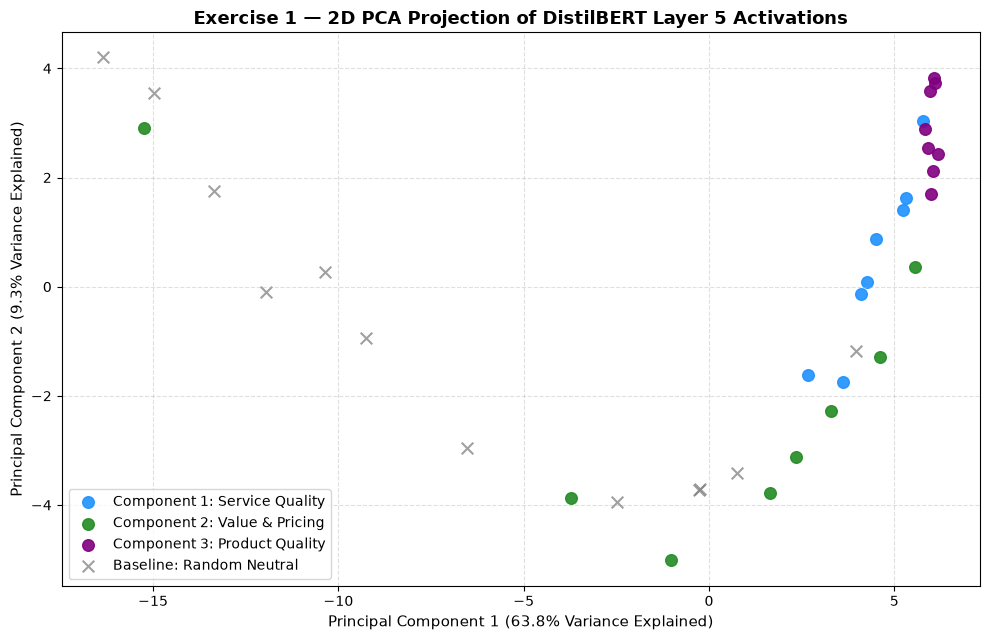

Total Explained Variance by First 2 Principal Components: 73.06%


In [9]:
# Stack all activation components
all_activations = np.vstack([act_service, act_value, act_quality, act_random])

# Fit 2D PCA projection
pca = PCA(n_components=2, random_state=SEED)
acts_pca = pca.fit_transform(all_activations)

# Slicing indices for each component
n_s = len(concept_service)
n_v = len(concept_value)
n_q = len(concept_quality)
n_r = len(random_baseline)

pca_service = acts_pca[:n_s]
pca_value   = acts_pca[n_s : n_s + n_v]
pca_quality = acts_pca[n_s + n_v : n_s + n_v + n_q]
pca_random  = acts_pca[n_s + n_v + n_q :]

# Plotting
plt.figure(figsize=(10, 6.5))
plt.scatter(pca_service[:, 0], pca_service[:, 1], c='dodgerblue', label='Component 1: Service Quality', s=70, alpha=0.9)
plt.scatter(pca_value[:, 0],   pca_value[:, 1],   c='forestgreen', label='Component 2: Value & Pricing', s=70, alpha=0.9)
plt.scatter(pca_quality[:, 0], pca_quality[:, 1], c='purple',      label='Component 3: Product Quality', s=70, alpha=0.9)
plt.scatter(pca_random[:, 0],  pca_random[:, 1],  c='gray',        label='Baseline: Random Neutral', marker='x', s=70, alpha=0.75)

plt.title(f"Exercise 1 — 2D PCA Projection of DistilBERT Layer {TARGET_LAYER_INDEX} Activations", fontsize=13, fontweight='bold')
plt.xlabel(f"Principal Component 1 ({pca.explained_variance_ratio_[0]:.1%} Variance Explained)", fontsize=11)
plt.ylabel(f"Principal Component 2 ({pca.explained_variance_ratio_[1]:.1%} Variance Explained)", fontsize=11)
plt.legend(frameon=True, fontsize=10, loc='best')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

print(f"Total Explained Variance by First 2 Principal Components: {sum(pca.explained_variance_ratio_):.2%}")